In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import anndata as ad
import scanpy as sc
import squidpy as sq

C:\Users\tpeng\AppData\Local\Programs\Python\Python312\Lib\site-packages\dask\dataframe\__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
C:\Users\tpeng\AppData\Local\Programs\Python\Python312\Lib\site-packages\datashader\__init__.py:6: FutureWarning: param.version.Version has been deprecated and will be removed in a future version.
  __version__ = str(param.version.Version(fpath=__file__, archive_commit="$Format:%h$",
C:\Users\tpeng\AppData\Local\Programs\Python\Python312\Lib\site-packages\param\version.py:200: FutureWarning: param.version.run_cmd has been deprecated and will be removed in a future version.
  remotes = run_cmd([cmd, 'remote', '-v'],
C:\Users\tpeng\AppData\Local\Programs\Python\Python312\Lib\site-packages\pyct\__init__.py:8: Future

In [2]:
sc.settings.autosave = True  # save figures, do not show them
 # set sufficiently high resolution for saving
sc.settings.set_figure_params(scanpy=True, dpi=80, dpi_save=300, frameon=True, vector_friendly=True, fontsize=16, color_map=None, format='png', transparent=True, ipython_format='png2x')

C:\Users\tpeng\AppData\Local\Temp\ipykernel_3560\3048756600.py:3: FutureWarning: Use `scanpy.set_figure_params` instead
  sc.settings.set_figure_params(scanpy=True, dpi=80, dpi_save=300, frameon=True, vector_friendly=True, fontsize=16, color_map=None, format='png', transparent=True, ipython_format='png2x')


In [3]:
import os
os.getcwd()

'C:\\Users\\tpeng\\Notebook'

## download the adata object "Xenium_Proseq_pt3_control.h5ad" from the GitHub page"

In [10]:
adata = sc.read ('C:\\Users\\tpeng\\adata_files\\Xenium_Proseq_pt3_control.h5ad')
adata

AnnData object with n_obs × n_vars = 7622 × 475
    obs: 'cell', 'centroid_x', 'centroid_y', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'barcodes', 'leiden', 'Cell_label_L3'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

C:\Users\tpeng\AppData\Local\Programs\Python\Python312\Lib\site-packages\squidpy\pl\_spatial_utils.py:982: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


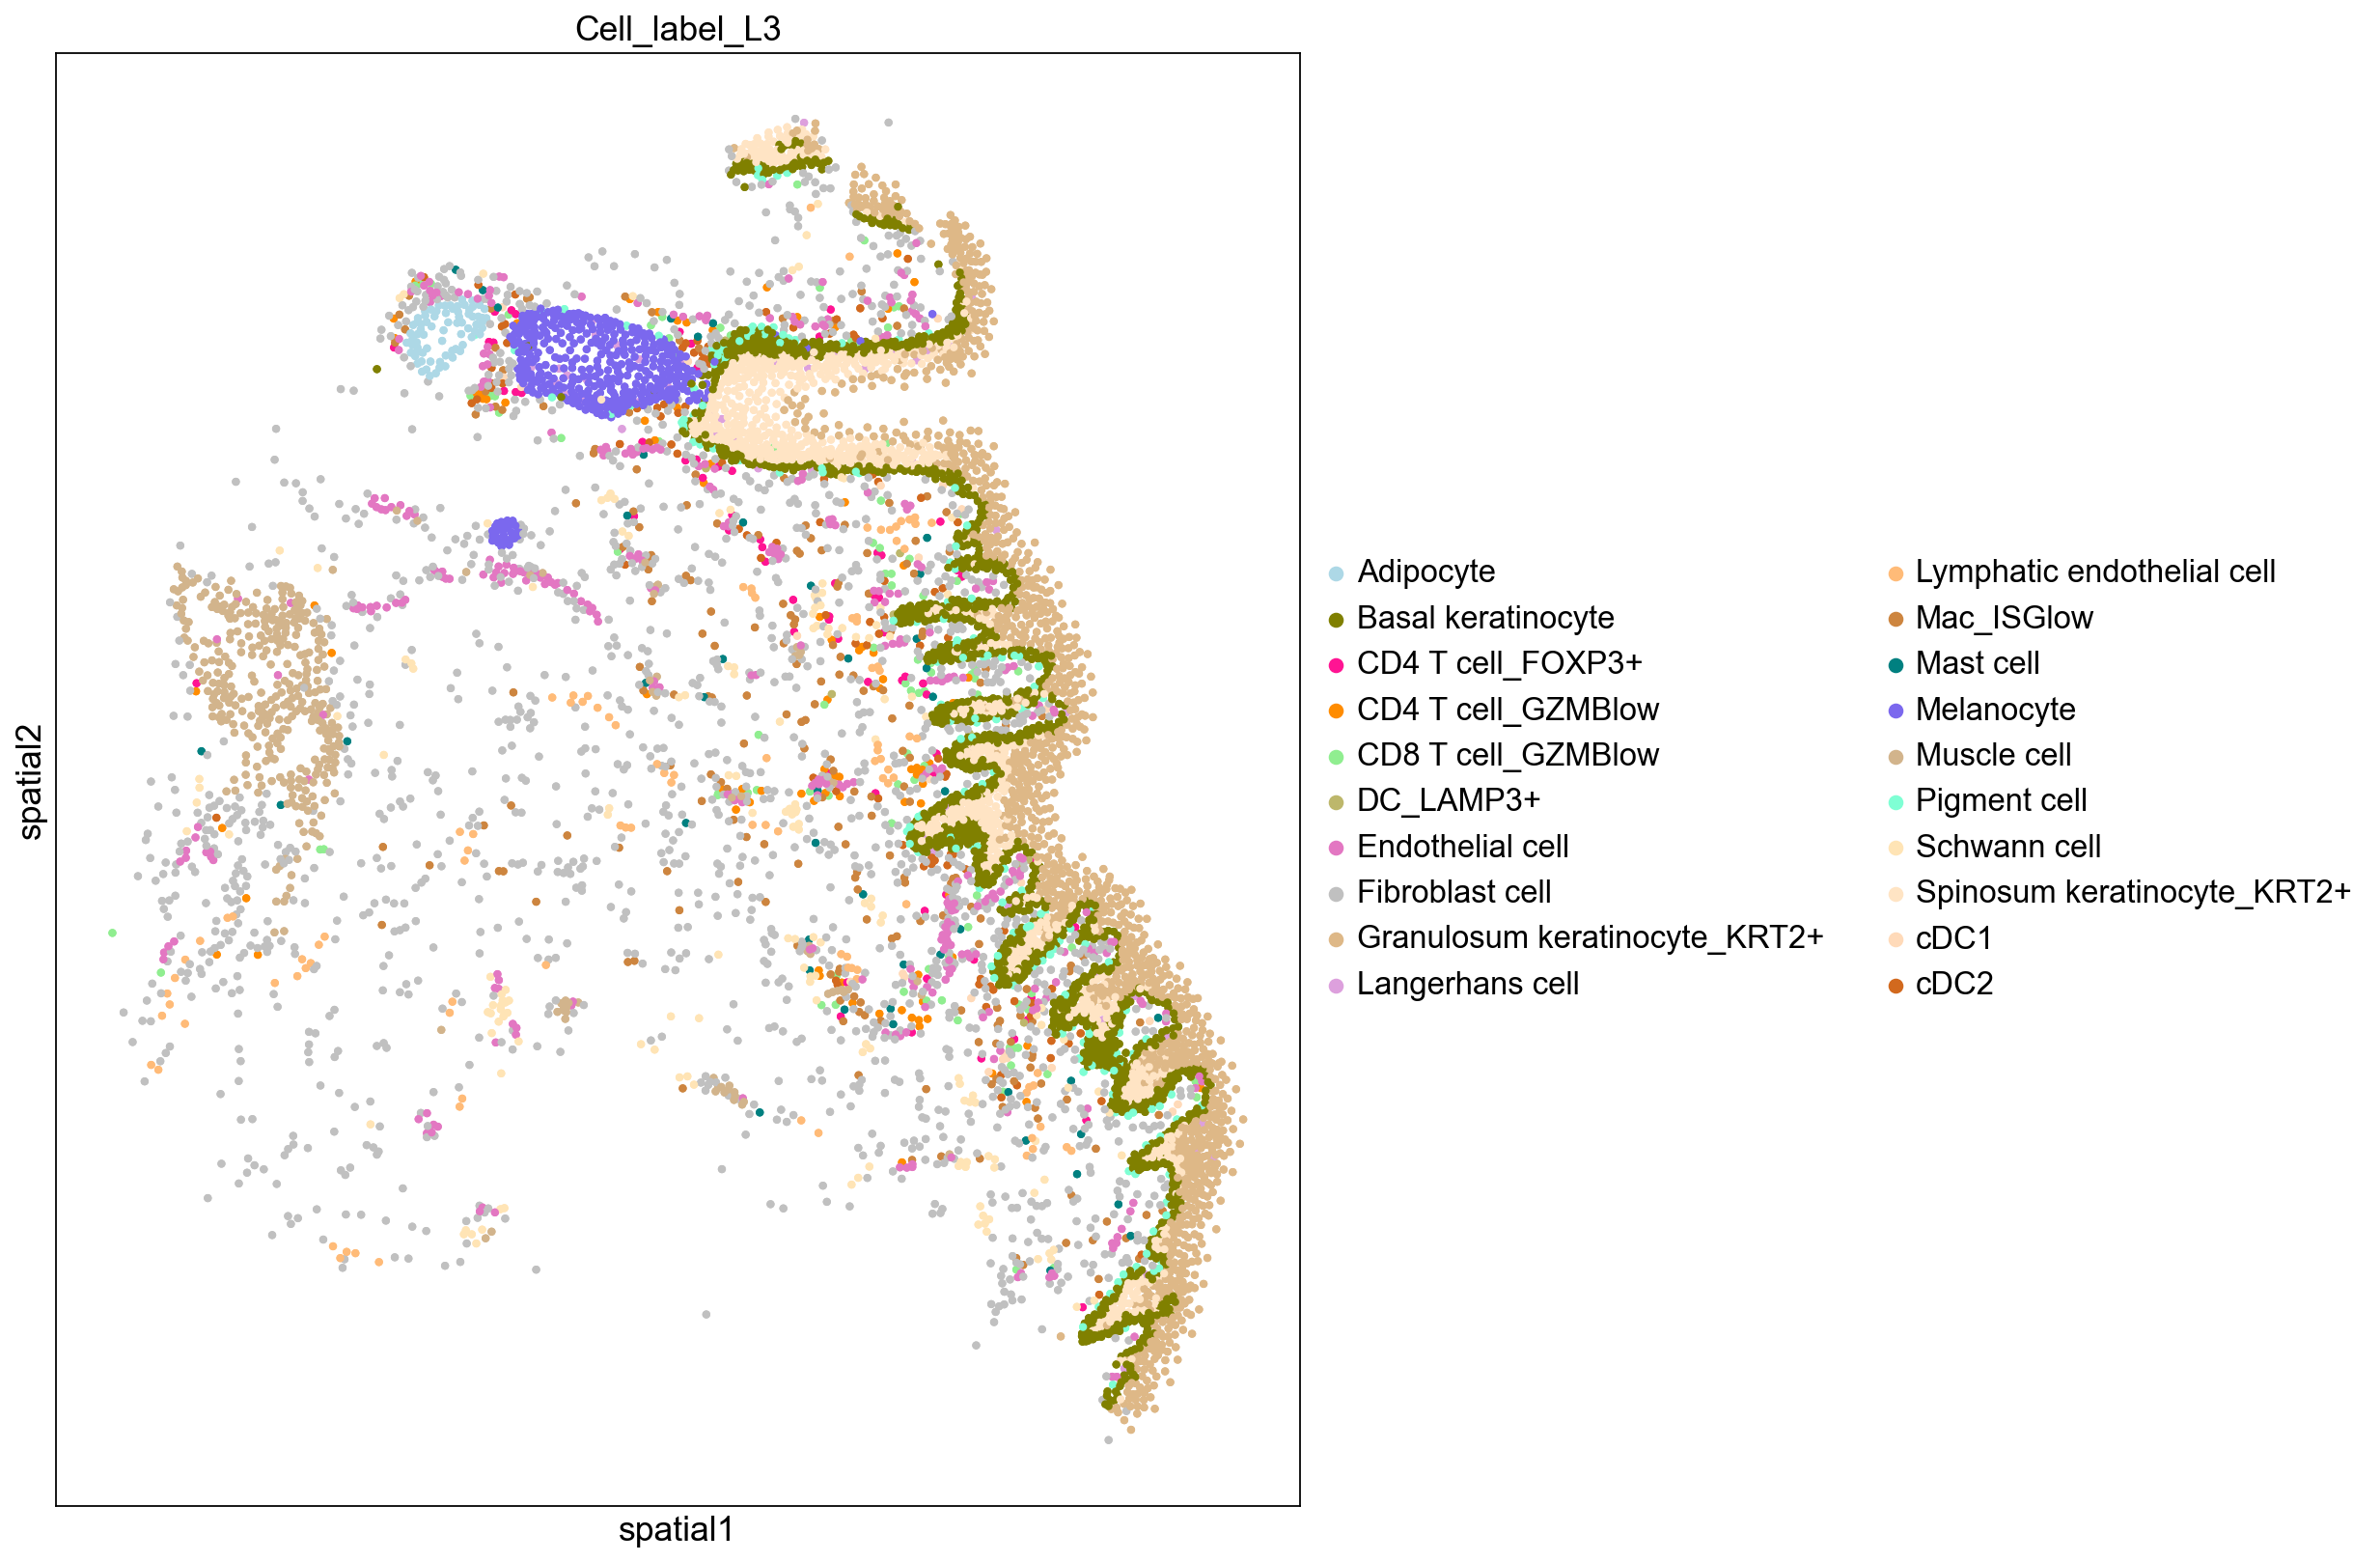

In [11]:
sq.pl.spatial_scatter(adata, color="Cell_label_L3",
                      shape=None, size=30, figsize = (20,10))

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.colors as mcolors

In [13]:
sorted(adata.obs['Cell_label_L3'].unique().tolist())

['Adipocyte',
 'Basal keratinocyte',
 'CD4 T cell_FOXP3+',
 'CD4 T cell_GZMBlow',
 'CD8 T cell_GZMBlow',
 'DC_LAMP3+',
 'Endothelial cell',
 'Fibroblast cell',
 'Granulosum keratinocyte_KRT2+',
 'Langerhans cell',
 'Lymphatic endothelial cell',
 'Mac_ISGlow',
 'Mast cell',
 'Melanocyte',
 'Muscle cell',
 'Pigment cell',
 'Schwann cell',
 'Spinosum keratinocyte_KRT2+',
 'cDC1',
 'cDC2']

In [14]:
len(adata.obs['Cell_label_L3'].unique().tolist())

20

In [15]:
adata

AnnData object with n_obs × n_vars = 7622 × 475
    obs: 'cell', 'centroid_x', 'centroid_y', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'barcodes', 'leiden', 'Cell_label_L3'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [16]:
markers = ['KRT2','COL17A1','CD8A','CD3D','CD4','FOXP3','GZMB','PRF1','IFNG','CXCL8','CCL5','CXCL9','CXCL10','ISG15','CD28',
           'CD86','IL3RA','CD83','CD274','CD14','C1QA','CD1C','CLEC9A','LAMP3','CD1A','KIT','GATA2','CTLA4','HAVCR2','PDCD1','LAG3','MKI67', 'VWF']

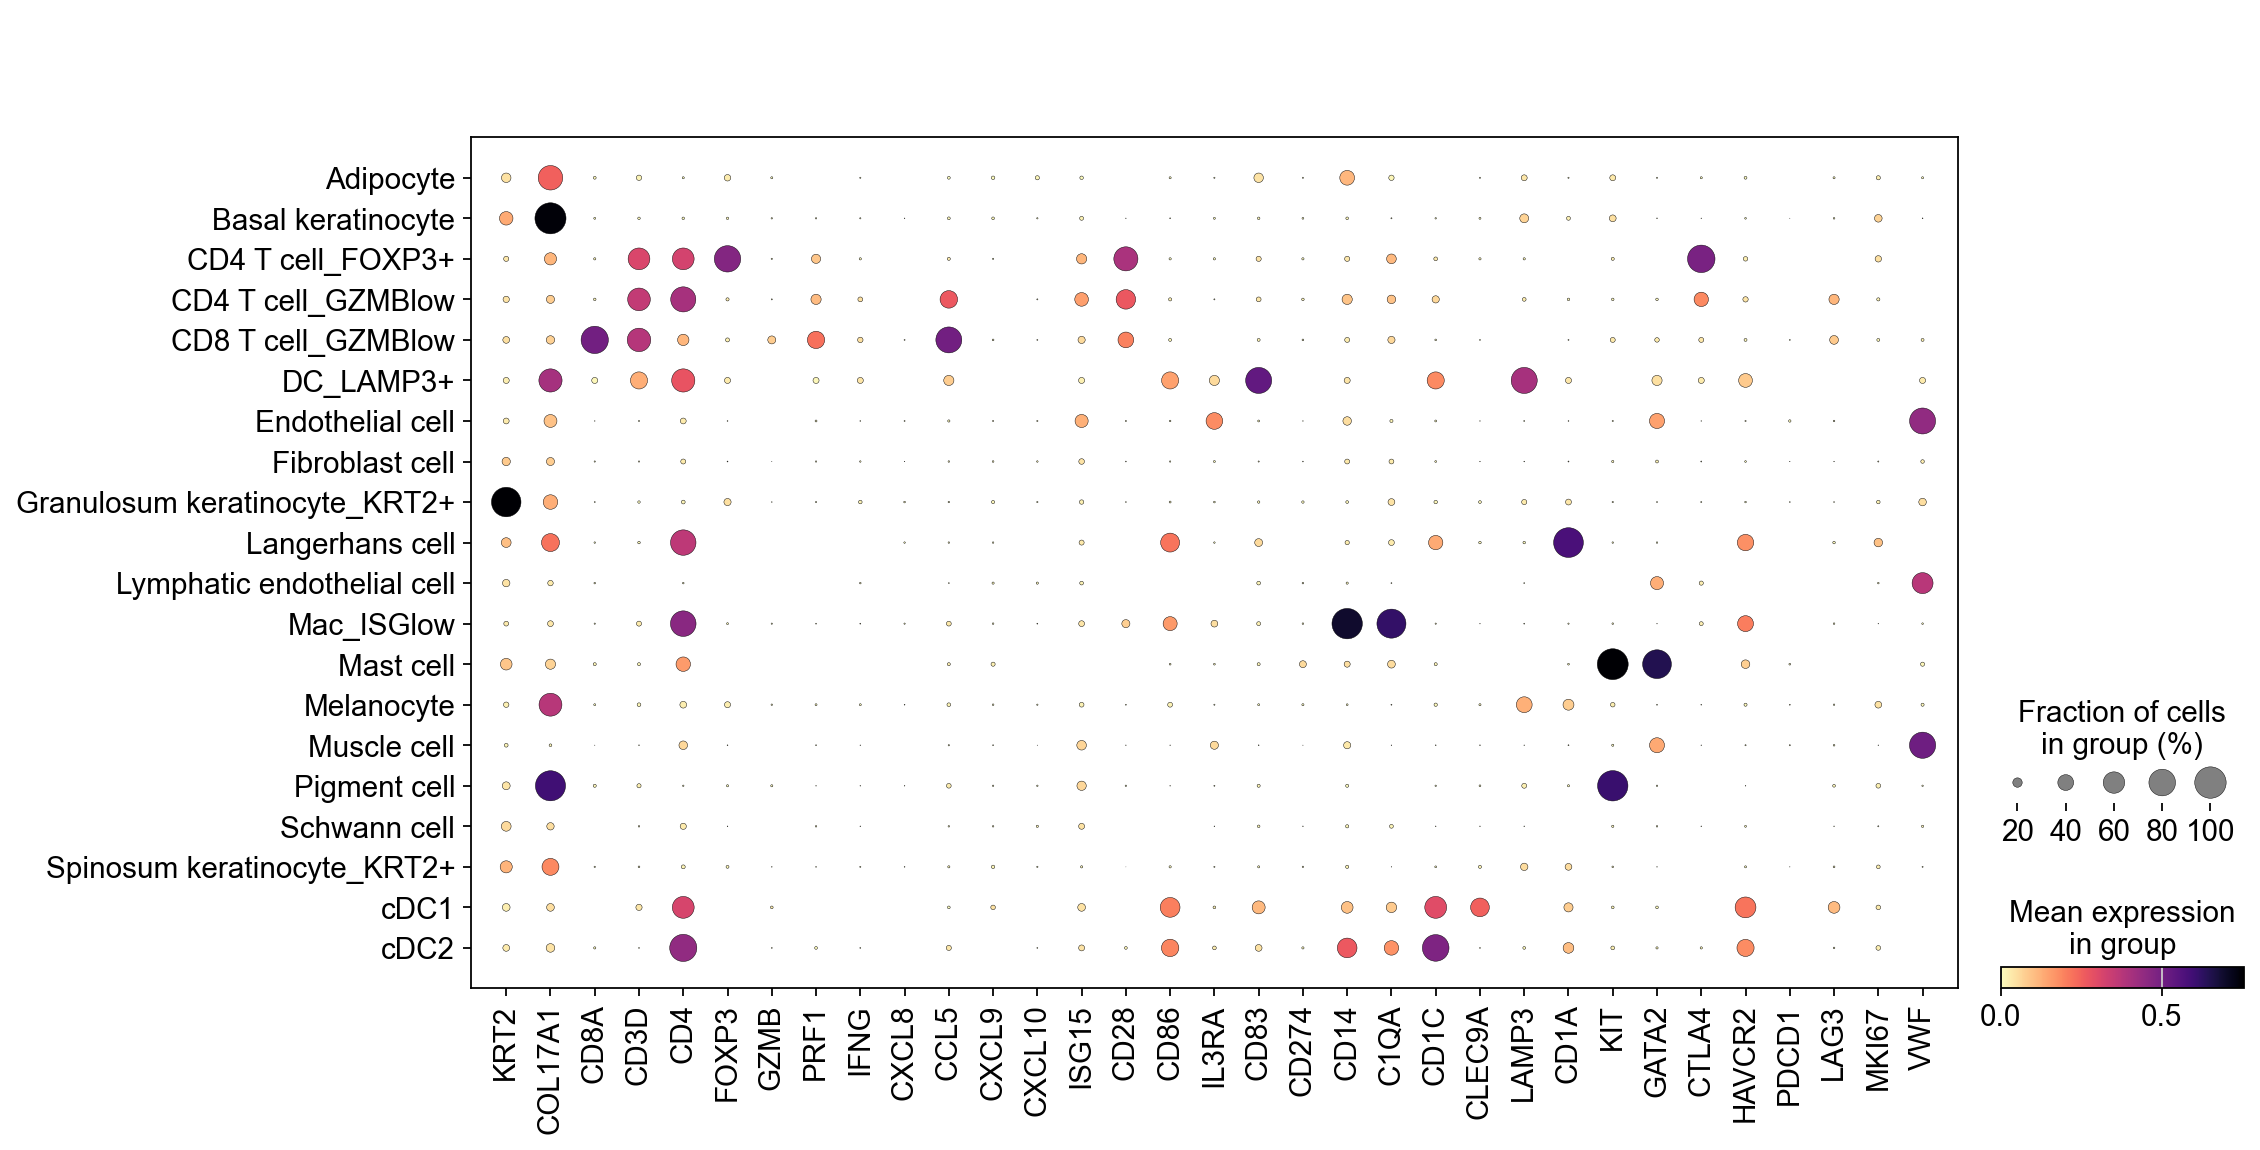

In [17]:
from matplotlib import rcParams
FIGSIZE = (8, 12)
sc.pl.dotplot(adata, markers, groupby='Cell_label_L3',cmap = 'magma_r')